# Retail demand forecasting and inventory policy evaluation (M5)

**One run produces:** accuracy tables with confidence intervals, a Diebold-Mariano test, a day-by-day
inventory simulation compared at *matched fill rate*, calibration/coverage checks, feature importance and an
ablation, and eight figures. Everything is written to `results/`.

**How to run:** put `calendar.csv`, `sell_prices.csv`, `sales_train_evaluation.csv` in `m5_data/`, then run the
cells top to bottom. Cell 9 (`main`) is the only slow one. For a first test set `CFG.n_origins = 1`.

**Design rules this code enforces (and tests in cell 8):**
1. Target = demand over days t+1 ... t+P, where P = review period + lead time. Every feature uses data up to day t only.
2. Every method (seasonal naive, moving average, SBA, TSB, LightGBM) is re-forecast at every origin with equal information.
3. Train, validation, calibration and test target windows never overlap (purged splits).
4. Each method's safety buffer comes from its own calibration errors.
5. Methods are compared at matched fill rate by interpolating each method's fill-rate / capital frontier, with SKU-bootstrap intervals.

## 1. Imports and configuration

In [1]:
import os, sys, json, math, time, warnings
from dataclasses import dataclass, field, asdict
from typing import List, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t as student_t

warnings.filterwarnings("ignore")
import lightgbm as lgb

try:
    from IPython.display import display
except Exception:          # plain python
    display = print

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "figure.dpi": 110})

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9a94"
MIN_ORIGIN = 56      # longest look-back used by the direct features


@dataclass
class Config:
    # ---- data
    data_dir: str = "m5_data/"
    out_dir: str = "results/"
    stores: List[str] = field(default_factory=lambda: ["CA_1"])   # all ten: CA_1..CA_4, TX_1..TX_3, WI_1..WI_3
    day_slice: Optional[tuple] = None        # None = all 1941 days; (1000, 1885) reproduces the paper's window
    synthetic: bool = False                  # True = run on generated data (smoke test only)
    # ---- inventory system
    review: int = 1                          # R: days between orders (1 = daily review)
    lead: int = 7                            # L: replenishment lead time (days)
    horizon: int = 28                        # H: simulated days per origin
    lost_sales: bool = True                  # unmet demand is lost (retail); False = backorders
    # ---- rolling-origin protocol
    n_origins: int = 3                       # number of rolling test origins (use 6-12 for the paper-grade run)
    step: int = 28                           # days between origins (= horizon, so test windows tile the timeline)
    cal_days: int = 140                      # calibration origins per test origin
    val_origins: int = 28                    # early-stopping origins
    train_stride: int = 3                    # spacing of training origins
    train_window: int = 730                  # days of training origins before the validation block
    # ---- models
    seeds: List[int] = field(default_factory=lambda: [42, 123])
    tweedie_power: float = 1.15
    rounds: int = 600
    lr: float = 0.05
    leaves: int = 31
    min_leaf: int = 50
    q_alpha: float = 0.95
    use_item_id: bool = True
    # ---- buffer grids (the parameter that is swept to trace a fill-rate / capital frontier)
    sigma_grid: List[float] = field(default_factory=lambda: [0, .25, .5, .75, 1.0, 1.28, 1.645, 2.0, 2.33, 2.75, 3.1, 3.5, 4.0])
    conf_grid: List[float] = field(default_factory=lambda: [.5, .6, .7, .8, .85, .9, .95, .975, .99, .995, .999])
    q_grid: List[float] = field(default_factory=lambda: [0, .25, .5, .75, 1.0, 1.5, 2.0, 3.0])
    target_fills: List[float] = field(default_factory=lambda: [0.90, 0.95, 0.98])
    # ---- inference
    boot: int = 500
    seed: int = 0
    run_ablation: bool = True
    ablation_origins: int = 1

    @property
    def P(self) -> int:                      # protection interval
        return self.review + self.lead

    @property
    def NE(self) -> int:                     # number of ordering epochs in the simulated window
        return int(math.ceil(self.horizon / self.review))


CFG = Config()

FORECASTERS = ["snaive", "ma28", "sba", "tsb", "lgbm"]
LABEL = {"snaive": "Seasonal naive", "ma28": "Moving average (28d)", "sba": "SBA (Croston)",
         "tsb": "TSB", "lgbm": "LightGBM (Tweedie)"}
METHOD_LABEL = {"sigma": "per-SKU sigma", "sigma_eb": "EB-shrunk sigma", "conformal": "conformal", "lgbm_q": "quantile spread"}

## 2. Data: calendar-day matrices (series x days)
Working on matrices (not row-shifted frames) keeps every lag on the calendar and makes the leakage test in cell 8 exact.

In [2]:
def _cum(A):
    return np.concatenate([np.zeros((A.shape[0], 1)), np.cumsum(A.astype(np.float64), axis=1)], axis=1)


def _ffill(A):
    n, T = A.shape
    idx = np.where(~np.isnan(A), np.arange(T)[None, :], 0)
    np.maximum.accumulate(idx, axis=1, out=idx)
    return A[np.arange(n)[:, None], idx]


class Panel:
    """Y: units sold; price: weekly price per day (NaN = item not listed that week, as encoded by M5)."""

    def __init__(self, series, dates, Y, price, event):
        self.series = series.reset_index(drop=True)
        self.dates = pd.DatetimeIndex(dates)
        self.Y = np.asarray(Y, dtype=np.float32)
        self.price = np.asarray(price, dtype=np.float32)
        self.event = np.asarray(event).astype(np.int8)
        self.n, self.T = self.Y.shape
        self.dow = self.dates.dayofweek.to_numpy()
        self.month = self.dates.month.to_numpy()
        self.listed = ~np.isnan(self.price)
        self.C = _cum(self.Y)
        self.C2 = _cum(self.Y.astype(np.float64) ** 2)
        self.Z = _cum(self.Y == 0)
        self.Lc = _cum(self.listed)
        pf = _ffill(self.price)
        pf = _ffill(pf[:, ::-1])[:, ::-1]
        pf = np.where(np.isnan(pf), np.nanmean(self.price), pf)
        self.price_filled = pf.astype(np.float32)
        self.Cp = _cum(pf)
        self.pmax = np.maximum.accumulate(pf, axis=1)
        idx = np.arange(self.T)[None, :]
        self.last_sale = np.maximum.accumulate(np.where(self.Y > 0, idx, -1), axis=1)
        self.Cwk = np.concatenate([[0], np.cumsum(self.dow >= 5)])
        self.Cev = np.concatenate([[0], np.cumsum(self.event)])
        self.dept_code = pd.factorize(self.series["dept_id"])[0]
        self.cat_code = pd.factorize(self.series["cat_id"])[0]

    def wsum(self, lo, hi):
        """Sum of Y over days lo..hi inclusive (integer arrays of equal length) -> [n, len]."""
        return self.C[:, np.asarray(hi) + 1] - self.C[:, np.asarray(lo)]


def load_m5_raw(cfg):
    d = cfg.data_dir
    cal = pd.read_csv(os.path.join(d, "calendar.csv"))
    sales = pd.read_csv(os.path.join(d, "sales_train_evaluation.csv"))
    prices = pd.read_csv(os.path.join(d, "sell_prices.csv"))
    return cal, sales, prices


def build_panel(raw, store, cfg):
    cal, sales, prices = raw
    s = sales[sales["store_id"] == store].reset_index(drop=True)
    if s.empty:
        raise ValueError(f"store {store} not found")
    dcols = [c for c in s.columns if c.startswith("d_")]
    if cfg.day_slice is not None:
        dcols = dcols[cfg.day_slice[0]:cfg.day_slice[1]]
    Y = s[dcols].to_numpy(dtype=np.float32)
    cal = cal.set_index("d").loc[dcols]
    weeks = cal["wm_yr_wk"].to_numpy()
    pw = prices[prices["store_id"] == store].pivot_table(index=["store_id", "item_id"], columns="wm_yr_wk", values="sell_price")
    keys = pd.MultiIndex.from_frame(s[["store_id", "item_id"]])
    P = pw.reindex(keys).reindex(columns=weeks).to_numpy(dtype=np.float32)
    return Panel(s[["store_id", "item_id", "dept_id", "cat_id"]], pd.to_datetime(cal["date"]).to_numpy(), Y, P,
                 cal["event_name_1"].notna().to_numpy())


def make_synthetic(n=300, T=900, seed=0):
    """Intermittent, seasonal, promotion-driven demand with late launches (for smoke tests only)."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2013-01-01", periods=T)
    dow = dates.dayofweek.to_numpy(); t = np.arange(T)
    event = rng.random(T) < 0.03
    base = np.exp(rng.normal(-0.4, 1.0, n))
    weekly = np.array([0.8, 0.8, 0.85, 0.9, 1.0, 1.4, 1.3])
    promo = rng.random((n, T)) < 0.04
    price = np.exp(rng.normal(1.0, 0.7, n))[:, None] * np.where(promo, 0.8, 1.0)
    mu = base[:, None] * weekly[dow][None, :] * (1 + 0.2 * np.sin(2 * np.pi * t / 365))[None, :]
    mu = mu * (1 + 0.3 * event[None, :]) * (1 + 0.5 * promo) * np.maximum(1 + rng.normal(0, .15, n)[:, None] * (t / T)[None, :], .2)
    r = 2.0
    Y = rng.negative_binomial(r, r / (r + mu)).astype(np.float32)
    launch = np.where(rng.random(n) < 0.2, rng.integers(0, 300, n), 0)
    un = t[None, :] < launch[:, None]
    Y[un] = 0
    price = price.astype(np.float32); price[un] = np.nan
    series = pd.DataFrame({"store_id": "S_1", "item_id": [f"ITEM_{i}" for i in range(n)],
                           "dept_id": [f"D_{i % 4}" for i in range(n)], "cat_id": [f"C_{i % 2}" for i in range(n)]})
    return Panel(series, dates, Y, price, event)

## 3. Features and forecasters
`lt_features` describes the situation at the end of day *t*. Price, weekday and event information for the next *P* days
is treated as known in advance (a planned promotion calendar), exactly as in the original study.

In [3]:
def lt_features(panel, t, P, use_item_id=True):
    t = np.asarray(t); n, m = panel.n, len(t)
    if t.min() < MIN_ORIGIN:
        raise ValueError(f"origins must be >= {MIN_ORIGIN}")
    C, f = panel.C, {}
    for k in (7, 14, 28, 56):
        f[f"mean{k}"] = (C[:, t + 1] - C[:, t + 1 - k]) / k
    s1 = C[:, t + 1] - C[:, t - 27]; s2 = panel.C2[:, t + 1] - panel.C2[:, t - 27]
    f["std28"] = np.sqrt(np.maximum(s2 / 28 - (s1 / 28) ** 2, 0))
    f["zero28"] = (panel.Z[:, t + 1] - panel.Z[:, t - 27]) / 28
    f["y_last"] = panel.Y[:, t]
    ls = panel.last_sale[:, t]
    f["days_since_sale"] = np.where(ls < 0, 120, np.minimum(t[None, :] - ls, 120))
    f["price_now"] = panel.price_filled[:, t]
    pw = (panel.Cp[:, t + P + 1] - panel.Cp[:, t + 1]) / P
    f["price_win"] = pw
    f["disc_win"] = 1 - pw / panel.pmax[:, t]
    for name, arr in (("wk_days", panel.Cwk), ("ev_days", panel.Cev)):
        f[name] = np.broadcast_to((arr[t + P + 1] - arr[t + 1])[None, :], (n, m))
    f["dow_next"] = np.broadcast_to(panel.dow[t + 1][None, :], (n, m))
    f["month_next"] = np.broadcast_to(panel.month[t + 1][None, :], (n, m))
    X = {k: np.asarray(v, dtype=np.float32).ravel() for k, v in f.items()}
    if use_item_id:
        X["series_id"] = np.repeat(np.arange(n, dtype=np.int32), m)
    X["dept_id"] = np.repeat(panel.dept_code.astype(np.int32), m)
    X["cat_id"] = np.repeat(panel.cat_code.astype(np.int32), m)
    return pd.DataFrame(X)            # row order: series-major, origin-minor (matches reshape(n, m))


def listed_all(panel, t, P, back=27):
    t = np.asarray(t)
    return (panel.Lc[:, t + P + 1] - panel.Lc[:, t - back]) == (back + P + 1)


# ---- benchmarks: all re-forecast at every origin from data <= t
def fc_snaive(panel, t, P):
    t = np.asarray(t); out = np.zeros((panel.n, len(t)))
    for h in range(1, P + 1):
        out += panel.Y[:, t + h - 7 * math.ceil(h / 7)]       # same weekday, last observed week
    return out


def fc_ma(panel, t, P, k=28):
    t = np.asarray(t)
    return P * (panel.C[:, t + 1] - panel.C[:, t + 1 - k]) / k


def _init_state(Y, act, warm=28):
    I = (Y[:, :warm] > 0) & act[:, :warm]
    p0 = I.sum(1) / np.maximum(act[:, :warm].sum(1), 1)
    with np.errstate(all="ignore"):
        z0 = np.nanmean(np.where(I, Y[:, :warm], np.nan), axis=1)
    return p0, np.where(np.isnan(z0), 1.0, z0)


def tsb_rates(Y, act, a_p=0.1, a_z=0.1):
    """Teunter-Syntetos-Babai. rate[:, t] uses data <= t. State is frozen on days the item is not listed."""
    n, T = Y.shape; p, z = _init_state(Y, act)
    rate = np.zeros((n, T), np.float32)
    for t in range(T):
        hit = (Y[:, t] > 0) & act[:, t]
        p = np.where(act[:, t], p + a_p * (hit - p), p)
        z = np.where(hit, z + a_z * (Y[:, t] - z), z)
        rate[:, t] = p * z
    return rate


def sba_rates(Y, act, a=0.1):
    """Croston with the Syntetos-Boylan bias correction."""
    n, T = Y.shape; p0, z = _init_state(Y, act)
    q = 1.0 / np.maximum(p0, 1 / 28); since = np.zeros(n)
    rate = np.zeros((n, T), np.float32)
    for t in range(T):
        since += act[:, t]
        hit = (Y[:, t] > 0) & act[:, t]
        z = np.where(hit, z + a * (Y[:, t] - z), z)
        q = np.where(hit, q + a * (since - q), q)
        since = np.where(hit, 0, since)
        rate[:, t] = (1 - a / 2) * z / q
    return rate


# ---- LightGBM
CAT = ["series_id", "dept_id", "cat_id"]


def cat_cols(cfg, drop=()):
    return [c for c in CAT if (c != "series_id" or cfg.use_item_id) and c not in drop]


def build_xy(panel, origins, cfg, drop=()):
    X = lt_features(panel, origins, cfg.P, cfg.use_item_id)
    if drop:
        X = X.drop(columns=[c for c in drop if c in X.columns])
    y = panel.wsum(np.asarray(origins) + 1, np.asarray(origins) + cfg.P).ravel()
    ok = listed_all(panel, origins, cfg.P).ravel()
    return X, y, ok


def lgb_params(cfg, objective, seed):
    p = dict(objective=objective, learning_rate=cfg.lr, num_leaves=cfg.leaves, feature_fraction=0.8,
             bagging_fraction=0.8, bagging_freq=1, min_data_in_leaf=cfg.min_leaf, verbosity=-1, seed=seed, num_threads=0)
    if objective == "tweedie":
        p.update(tweedie_variance_power=cfg.tweedie_power, metric="tweedie")
    if objective == "quantile":
        p.update(alpha=cfg.q_alpha, metric="quantile")
    return p


def fit_boosters(panel, split, cfg, drop=(), with_quantile=True, seeds=None):
    Xtr, ytr, oktr = build_xy(panel, split["train"], cfg, drop)
    Xva, yva, okva = build_xy(panel, split["val"], cfg, drop)
    cats = [c for c in cat_cols(cfg, drop) if c in Xtr.columns]
    Xtr, ytr, Xva, yva = Xtr.loc[oktr], ytr[oktr], Xva.loc[okva], yva[okva]

    def fit(objective, seed):
        d_tr = lgb.Dataset(Xtr, label=ytr, categorical_feature=cats)
        d_va = lgb.Dataset(Xva, label=yva, categorical_feature=cats, reference=d_tr)
        return lgb.train(lgb_params(cfg, objective, seed), d_tr, num_boost_round=cfg.rounds, valid_sets=[d_va],
                         callbacks=[lgb.early_stopping(30, verbose=False)])
    point = [fit("tweedie", s) for s in (seeds or cfg.seeds)]
    quant = fit("quantile", cfg.seeds[0]) if with_quantile else None
    return dict(point=point, quantile=quant, drop=tuple(drop))


def predict_point(models, panel, t, cfg):
    X = lt_features(panel, t, cfg.P, cfg.use_item_id).drop(columns=list(models["drop"]), errors="ignore")
    pr = np.mean([np.clip(m.predict(X), 0, None) for m in models["point"]], axis=0)
    return pr.reshape(panel.n, len(t))


def predict_quantile(models, panel, t, cfg):
    X = lt_features(panel, t, cfg.P, cfg.use_item_id).drop(columns=list(models["drop"]), errors="ignore")
    return np.clip(models["quantile"].predict(X), 0, None).reshape(panel.n, len(t))

## 4. Safety buffers and the inventory simulator
**Buffer rules** (each uses the method's *own* calibration errors; `F` = forecast of next-P-day demand, `E` = actual - forecast):
- `sigma`: `S = F + m * sigma_i` (per-SKU standard deviation of E)
- `sigma_eb`: same, with sigma_i shrunk toward a department x volume-tercile group by empirical Bayes (method of moments, kurtosis-corrected sampling variance)
- `conformal`: `S = F + q_tau * sqrt(F+1)`, where `q_tau` is the tau-quantile of volume-scaled errors pooled within the group
- `lgbm_q`: `S = F + m * max(Q95 - F, 0)` using the LightGBM quantile model

**Simulator:** an order is placed at the end of every R-th day, bringing the inventory position up to `S`, and arrives after `L` full days.
Fill rate is demand-weighted (units served / units demanded). Initial stock is the policy's own `S` at the origin.

In [4]:
def make_groups(dept_code, vol, bins=3):
    g = np.zeros(len(vol), dtype=int)
    for d in np.unique(dept_code):
        idx = np.where(dept_code == d)[0]
        r = vol[idx].argsort().argsort()
        g[idx] = d * bins + np.minimum((r * bins) // max(len(idx), 1), bins - 1)
    return g


def eb_sigma(E, F, groups, n_eff):
    """Shrink per-SKU error variance toward its group. Works on the variance-to-volume ratio s = var/(mean F + 1).
    Weight w = tau2/(tau2 + sampling variance), with sampling variance = s^2 (kurtosis-1)/n_eff; n_eff = number of
    non-overlapping windows, NOT the number of overlapping daily origins."""
    n = E.shape[0]
    var = E.var(axis=1, ddof=1); scale = F.mean(axis=1) + 1.0; s = var / scale
    zc = (E - E.mean(1, keepdims=True)) / np.sqrt(np.maximum(var, 1e-12))[:, None]
    kurt = np.clip((zc ** 4).mean(1), 1.5, 50.0)
    samp = s ** 2 * (kurt - 1.0) / max(n_eff - 1.0, 1.0)
    s_shr, w = s.copy(), np.ones(n)
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        if len(idx) < 5:
            continue
        lo, hi = np.quantile(s[idx], [0.01, 0.99])
        sw = np.clip(s[idx], lo, hi)
        tau2 = max(sw.var(ddof=1) - samp[idx].mean(), 0.0)
        wi = tau2 / (tau2 + samp[idx] + 1e-12)
        w[idx] = wi
        s_shr[idx] = wi * s[idx] + (1 - wi) * sw.mean()
    return np.sqrt(np.maximum(s_shr * scale, 0)), w


def calib_stats(F, A, dept_code, cfg):
    E = A - F
    groups = make_groups(dept_code, F.mean(axis=1))
    sig_eb, w = eb_sigma(E, F, groups, max(F.shape[1] / cfg.P, 2.0))
    return dict(sigma=E.std(axis=1, ddof=1), sigma_eb=sig_eb, w=w, groups=groups, Rs=E / np.sqrt(F + 1.0), cq={})


def conf_offset(st, tau):
    if tau not in st["cq"]:
        q = np.zeros(len(st["groups"]))
        for g in np.unique(st["groups"]):
            idx = st["groups"] == g
            q[idx] = np.quantile(st["Rs"][idx], tau)
        st["cq"][tau] = q
    return st["cq"][tau]


def make_S(method, param, F, st, Fq=None):
    if method == "sigma":
        S = F + param * st["sigma"][:, None]
    elif method == "sigma_eb":
        S = F + param * st["sigma_eb"][:, None]
    elif method == "conformal":
        S = F + conf_offset(st, param)[:, None] * np.sqrt(F + 1.0)
    elif method == "lgbm_q":
        S = F + param * np.maximum(Fq - F, 0)
    else:
        raise ValueError(method)
    return np.ceil(np.maximum(S, 0))


def simulate(Yh, S, R, L, lost_sales=True):
    """Yh [n, H] demand after the origin; S [n, NE] order-up-to levels (column e = epoch at origin + e*R)."""
    n, H = Yh.shape; NE = S.shape[1]
    on_hand = S[:, 0].astype(float).copy(); pipeline = np.zeros(n)
    arrivals = np.zeros((n, H + L + 2))
    lost_tot, inv_sum = np.zeros(n), np.zeros(n)
    cyc = np.zeros((n, NE), dtype=bool)
    for d in range(1, H + 1):
        arr = arrivals[:, d]; on_hand += arr; pipeline -= arr
        dem = Yh[:, d - 1]
        if lost_sales:
            sold = np.minimum(on_hand, dem); on_hand -= sold
        else:
            sold = np.minimum(np.maximum(on_hand, 0), dem); on_hand -= dem
        lost = dem - sold; lost_tot += lost
        cyc[:, min((d - 1) // R, NE - 1)] |= lost > 0
        inv_sum += np.maximum(on_hand, 0)
        if d % R == 0 and d // R < NE:
            q = np.maximum(S[:, d // R] - (on_hand + pipeline), 0)
            arrivals[:, d + L + 1] += q; pipeline += q
    return dict(lost=lost_tot, avg_on_hand=inv_sum / H, so=cyc.sum(axis=1))

## 5. Rolling-origin protocol (purged splits)
For each test origin `T0`: calibration origins end at `T0-P` (their targets end at `T0`); validation targets end at the first
calibration origin; training targets end before the first validation origin. No target window overlaps another split's.

In [5]:
def origin_list(T, cfg):
    last = T - 1 - (cfg.horizon - 1) - cfg.P
    return sorted(last - k * cfg.step for k in range(cfg.n_origins))


def make_split(T0, cfg):
    P = cfg.P
    c1 = T0 - P; c0 = c1 - cfg.cal_days + 1
    v1 = c0 - P; v0 = v1 - cfg.val_origins + 1
    tr1 = v0 - P - 1; tr0 = max(MIN_ORIGIN, tr1 - cfg.train_window)
    if tr1 - tr0 < 120:
        return None
    assert tr1 + P < v0 + 1 and v1 + P <= c0 and c1 + P <= T0, "split windows overlap"
    return dict(cal=np.arange(c0, c1 + 1), val=np.arange(v0, v1 + 1), train=np.arange(tr0, tr1 + 1, cfg.train_stride),
                c0=c0, c1=c1, v0=v0, v1=v1, tr0=tr0, tr1=tr1, T0=T0)


def forecaster_fns(panel, rates, models, cfg):
    P = cfg.P
    return {"snaive": lambda t: fc_snaive(panel, t, P), "ma28": lambda t: fc_ma(panel, t, P, 28),
            "sba": lambda t: P * rates["sba"][:, np.asarray(t)], "tsb": lambda t: P * rates["tsb"][:, np.asarray(t)],
            "lgbm": lambda t: predict_point(models, panel, t, cfg)}


def policy_list():
    pol = [(f, m) for f in FORECASTERS for m in ("sigma", "sigma_eb", "conformal")]
    return pol + [("lgbm", "lgbm_q")]


def grid_for(method, cfg):
    return {"sigma": cfg.sigma_grid, "sigma_eb": cfg.sigma_grid, "conformal": cfg.conf_grid, "lgbm_q": cfg.q_grid}[method]


def run_origin(panel, T0, cfg, rates, R_acc, log=print):
    sp = make_split(T0, cfg)
    if sp is None:
        log(f"  T0={T0}: not enough history, skipped"); return
    P, H, NE = cfg.P, cfg.horizon, cfg.NE
    last = T0 + H - 1 + P; first = sp["c0"] - 27
    act = (panel.Lc[:, last + 1] - panel.Lc[:, first]) == (last - first + 1)
    idx = np.where(act)[0]
    if len(idx) < 50:
        log(f"  T0={T0}: only {len(idx)} continuously listed SKUs, skipped"); return
    t0 = time.time()
    models = fit_boosters(panel, sp, cfg)
    fns = forecaster_fns(panel, rates, models, cfg)
    cal_o = sp["cal"]; ta_o = np.arange(T0, T0 + H); te_o = T0 + cfg.review * np.arange(NE)
    dept = panel.dept_code[idx]
    Yh = panel.Y[idx, T0 + 1:T0 + H + 1].astype(np.float64)
    price = panel.price_filled[idx, T0 + 1:T0 + H + 1].mean(1)
    dem = Yh.sum(1)
    R_acc["sid"].append(idx); R_acc["dem"].append(dem); R_acc["T0"].append(np.full(len(idx), T0))
    Fe, Ae, st = {}, panel.wsum(te_o + 1, te_o + P)[idx], {}
    for f, fn in fns.items():
        Fa, Aa = fn(ta_o)[idx], panel.wsum(ta_o + 1, ta_o + P)[idx]
        err = Aa - Fa
        a = R_acc["acc"][f]
        a["abs"].append(np.abs(err).sum(1)); a["sq"].append((err ** 2).sum(1)); a["y"].append(Aa.sum(1)); a["err"].append(err.sum(1))
        R_acc["daily"][f]["abs"].append(np.abs(err).mean(0)); R_acc["daily"][f]["sq"].append((err ** 2).mean(0))
        Fe[f] = fn(te_o)[idx]
        st[f] = calib_stats(fn(cal_o)[idx], panel.wsum(cal_o + 1, cal_o + P)[idx], dept, cfg)
    Fq = predict_quantile(models, panel, te_o, cfg)[idx]
    R_acc["info"].append(dict(T0=T0, n_sku=len(idx), shrink_w=float(np.mean(st["lgbm"]["w"])),
                              iters=int(np.mean([m.best_iteration or cfg.rounds for m in models["point"]])),
                              train_rows=int(len(sp["train"]) * panel.n), seconds=None))
    gain = models["point"][0].feature_importance(importance_type="gain")
    R_acc["imp"].append(pd.Series(gain / max(gain.sum(), 1e-9), index=models["point"][0].feature_name()))
    for (f, m) in policy_list():
        rec = R_acc["pol"][f"{f}|{m}"]
        lost, cap, cov, so = [], [], [], []
        for prm in grid_for(m, cfg):
            S = make_S(m, prm, Fe[f], st[f], Fq if m == "lgbm_q" else None)
            r = simulate(Yh, S, cfg.review, cfg.lead, cfg.lost_sales)
            lost.append(r["lost"]); cap.append(r["avg_on_hand"] * price); so.append(r["so"]); cov.append((Ae <= S).sum(1))
        rec["lost"].append(np.array(lost)); rec["cap"].append(np.array(cap)); rec["cov"].append(np.array(cov)); rec["so"].append(np.array(so))
    R_acc["info"][-1]["seconds"] = round(time.time() - t0, 1)
    log(f"  T0={T0}: {len(idx)} SKUs, {R_acc['info'][-1]['iters']} boosting rounds, {R_acc['info'][-1]['seconds']}s")


def new_acc():
    return dict(sid=[], dem=[], T0=[], info=[], imp=[],
                acc={f: dict(abs=[], sq=[], y=[], err=[]) for f in FORECASTERS},
                daily={f: dict(abs=[], sq=[]) for f in FORECASTERS},
                pol={f"{f}|{m}": dict(lost=[], cap=[], cov=[], so=[]) for f, m in policy_list()})


def run_store(panel, cfg, name="store", log=print):
    log(f"[{name}] {panel.n} SKUs x {panel.T} days; protection interval P={cfg.P}")
    rates = {"sba": sba_rates(panel.Y, panel.listed), "tsb": tsb_rates(panel.Y, panel.listed)}
    acc = new_acc()
    for T0 in origin_list(panel.T, cfg):
        run_origin(panel, T0, cfg, rates, acc, log)
    return acc


def combine(accs, offsets):
    """Concatenate per-store accumulators into arrays; SKU ids are offset so SKUs from different stores stay distinct."""
    R = dict(info=[], imp=[], acc={}, daily={}, pol={}, n_sku=int(sum(o[1] for o in offsets)))
    R["sid"] = np.concatenate([np.concatenate(a["sid"]) + off for a, (off, _) in zip(accs, offsets)])
    R["dem"] = np.concatenate([np.concatenate(a["dem"]) for a in accs])
    R["T0"] = np.concatenate([np.concatenate(a["T0"]) for a in accs])
    for a in accs:
        R["info"] += a["info"]; R["imp"] += a["imp"]
    for f in FORECASTERS:
        R["acc"][f] = {k: np.concatenate([np.concatenate(a["acc"][f][k]) for a in accs]) for k in ("abs", "sq", "y", "err")}
    # daily loss series: average across stores for each (T0 order), then concatenate by ascending T0
    for f in FORECASTERS:
        R["daily"][f] = {k: np.concatenate([np.concatenate(a["daily"][f][k]) for a in accs]) for k in ("abs", "sq")} if len(accs) == 1 else \
            {k: np.mean([np.concatenate(a["daily"][f][k]) for a in accs], axis=0) for k in ("abs", "sq")}
    for key in accs[0]["pol"]:
        R["pol"][key] = {k: np.concatenate([np.concatenate(a["pol"][key][k], axis=1) for a in accs], axis=1) for k in ("lost", "cap", "cov", "so")}
    R["n_T0"] = len(set(R["T0"].tolist()))
    return R

## 6. Analysis: accuracy, DM test, matched-service capital, calibration, segments, ablation

In [6]:
def dm_hac(l_base, l_cand, h):
    """Diebold-Mariano with Newey-West/Bartlett variance (lag h-1) and the Harvey-Leybourne-Newbold correction.
    Positive statistic = candidate has the lower loss."""
    d = np.asarray(l_base) - np.asarray(l_cand); N = len(d); dc = d - d.mean()
    lrv = (dc * dc).mean()
    for k in range(1, h):
        lrv += 2 * (1 - k / h) * (dc[k:] * dc[:-k]).mean()
    stat = d.mean() / np.sqrt(max(lrv, 1e-12) / N) * np.sqrt(max((N + 1 - 2 * h + h * (h - 1) / N) / N, 1e-6))
    return float(stat), float(2 * (1 - student_t.cdf(abs(stat), N - 1)))


def sku_sums(R, arr):
    return np.bincount(R["sid"], weights=arr, minlength=R["n_sku"])


def boot_weights(R, cfg):
    rng = np.random.default_rng(cfg.seed)
    return np.stack([np.bincount(rng.integers(0, R["n_sku"], R["n_sku"]), minlength=R["n_sku"]) for _ in range(cfg.boot)]).astype(float)


def cap_at_fill(fill, cap, target):
    o = np.argsort(fill); f = np.maximum.accumulate(fill[o]); c = np.maximum.accumulate(cap[o])
    return np.nan if (target < f[0] or target > f[-1]) else float(np.interp(target, f, c))


def accuracy_table(R, cfg, W):
    H = cfg.horizon; cnt = np.bincount(R["sid"], minlength=R["n_sku"]) * H
    rows = []
    for f in FORECASTERS:
        a = R["acc"][f]
        s = {k: sku_sums(R, a[k]) for k in ("abs", "sq", "y", "err")}
        def metrics(w):
            n = (w * cnt).sum(); y = (w * s["y"]).sum()
            return (w * s["abs"]).sum() / n, np.sqrt((w * s["sq"]).sum() / n), 100 * (w * s["abs"]).sum() / y, 100 * (w * s["err"]).sum() / y
        pt = metrics(np.ones(R["n_sku"]))
        bs = np.array([metrics(w) for w in W])
        lo, hi = np.percentile(bs, 2.5, axis=0), np.percentile(bs, 97.5, axis=0)
        rows.append({"Forecaster": LABEL[f], "MAE": pt[0], "MAE lo": lo[0], "MAE hi": hi[0], "RMSE": pt[1], "RMSE lo": lo[1], "RMSE hi": hi[1],
                     "WAPE (%)": pt[2], "WAPE lo": lo[2], "WAPE hi": hi[2], "Bias (% of demand)": pt[3]})
    return pd.DataFrame(rows)


def dm_table(R, cfg):
    h = cfg.P - 1 if cfg.P > 1 else 1
    rows = []
    for base in FORECASTERS[:-1]:
        for loss in ("abs", "sq"):
            st_, p = dm_hac(R["daily"][base][loss], R["daily"]["lgbm"][loss], cfg.P)
            rows.append({"LightGBM vs": LABEL[base], "Loss": "absolute" if loss == "abs" else "squared",
                         "DM stat (+ = LightGBM better)": st_, "p-value": p, "origin-days": len(R["daily"][base][loss])})
    return pd.DataFrame(rows)


def frontier_table(R, cfg):
    rows = []
    n_obs = len(R["sid"]); NE = cfg.NE
    for key, rec in R["pol"].items():
        f, m = key.split("|"); grid = grid_for(m, cfg)
        fill = 1 - rec["lost"].sum(1) / R["dem"].sum()
        cap = rec["cap"].sum(1) / R["n_T0"]
        cov = rec["cov"].sum(1) / (n_obs * NE)
        csl = 1 - rec["so"].sum(1) / (n_obs * NE)
        for g, prm in enumerate(grid):
            nominal = norm.cdf(prm) if m in ("sigma", "sigma_eb") else (prm if m == "conformal" else np.nan)
            rows.append({"policy": key, "forecaster": f, "buffer": m, "param": prm, "nominal_coverage": nominal,
                         "empirical_coverage": cov[g], "fill_rate": fill[g], "cycle_service": csl[g], "capital": cap[g]})
    return pd.DataFrame(rows)


def matched_service_table(R, cfg, W):
    keys = list(R["pol"]); T = cfg.target_fills
    sku = {k: dict(lost=np.stack([sku_sums(R, r) for r in R["pol"][k]["lost"]]),
                   cap=np.stack([sku_sums(R, r) for r in R["pol"][k]["cap"]])) for k in keys}
    dem = sku_sums(R, R["dem"])
    def curve(k, w):
        fill = 1 - (sku[k]["lost"] @ w) / (dem @ w); cap = (sku[k]["cap"] @ w) / R["n_T0"]
        return np.array([cap_at_fill(fill, cap, t) for t in T])
    pt = {k: curve(k, np.ones(R["n_sku"])) for k in keys}
    bs = {k: np.stack([curve(k, w) for w in W]) for k in keys}                  # [B, targets]
    base = [k for k in keys if not k.startswith("lgbm")]
    rows = []
    for ti, t in enumerate(T):
        best = min(base, key=lambda k: np.nan_to_num(pt[k][ti], nan=np.inf))
        for k in keys:
            def sav(ref):
                s_pt = 100 * (pt[ref][ti] - pt[k][ti]) / pt[ref][ti]
                s_bs = 100 * (bs[ref][:, ti] - bs[k][:, ti]) / bs[ref][:, ti]
                return s_pt, np.nanpercentile(s_bs, 2.5), np.nanpercentile(s_bs, 97.5)
            f, m = k.split("|")
            row = {"target fill": f"{t:.0%}", "forecaster": LABEL[f], "buffer rule": METHOD_LABEL[m], "policy": k,
                   "capital ($)": pt[k][ti], "cap lo": np.nanpercentile(bs[k][:, ti], 2.5), "cap hi": np.nanpercentile(bs[k][:, ti], 97.5)}
            for nm, ref in (("vs best baseline", best), ("vs SBA+sigma", "sba|sigma")):
                s = sav(ref); row[f"saving {nm} (%)"], row[f"{nm} lo"], row[f"{nm} hi"] = s
            row["best baseline"] = best
            rows.append(row)
    return pd.DataFrame(rows)


def segment_table(R, cfg):
    H = cfg.horizon
    sku_mean = sku_sums(R, R["dem"]) / np.maximum(np.bincount(R["sid"], minlength=R["n_sku"]) * H, 1)
    seg_sku = pd.qcut(pd.Series(sku_mean).rank(method="first"), 4, labels=["Q1 slowest", "Q2", "Q3", "Q4 fastest"])
    seg = seg_sku.to_numpy()[R["sid"]]
    rows = []
    for f in FORECASTERS:
        a = R["acc"][f]
        for q in ["Q1 slowest", "Q2", "Q3", "Q4 fastest"]:
            mk = seg == q
            rows.append({"Forecaster": LABEL[f], "Demand quartile": q, "WAPE (%)": 100 * a["abs"][mk].sum() / a["y"][mk].sum(),
                         "Bias (% of demand)": 100 * a["err"][mk].sum() / a["y"][mk].sum()})
    return pd.DataFrame(rows)


def per_origin_table(R, cfg):
    rows = []
    for T0 in sorted(set(R["T0"].tolist())):
        mk = R["T0"] == T0
        for f in FORECASTERS:
            a = R["acc"][f]; rows.append({"T0": T0, "Forecaster": LABEL[f], "WAPE (%)": 100 * a["abs"][mk].sum() / a["y"][mk].sum()})
    return pd.DataFrame(rows)


def importance_table(R):
    return pd.concat(R["imp"], axis=1).mean(axis=1).sort_values(ascending=False).rename("gain share").to_frame()


def ablation_table(panel_list, cfg, log=print):
    variants = {"full model": (), "no SKU id": ("series_id",), "no price features": ("price_now", "price_win", "disc_win"),
                "no calendar/event": ("dow_next", "month_next", "wk_days", "ev_days"),
                "no long-run stats": ("mean56", "std28", "zero28", "days_since_sale")}
    tot = {v: [0.0, 0.0] for v in variants}
    for panel in panel_list:
        for T0 in origin_list(panel.T, cfg)[-cfg.ablation_origins:]:
            sp = make_split(T0, cfg)
            if sp is None:
                continue
            P, H = cfg.P, cfg.horizon
            last = T0 + H - 1 + P; first = sp["c0"] - 27
            idx = np.where((panel.Lc[:, last + 1] - panel.Lc[:, first]) == (last - first + 1))[0]
            ta = np.arange(T0, T0 + H); A = panel.wsum(ta + 1, ta + P)[idx]
            for v, drop in variants.items():
                mdl = fit_boosters(panel, sp, cfg, drop=drop, with_quantile=False, seeds=cfg.seeds[:1])
                F = predict_point(mdl, panel, ta, cfg)[idx]
                tot[v][0] += np.abs(A - F).sum(); tot[v][1] += A.sum()
            log(f"  ablation T0={T0} done")
    full = 100 * tot["full model"][0] / tot["full model"][1]
    return pd.DataFrame([{"Variant": v, "WAPE (%)": 100 * a / y, "Change vs full (pp)": 100 * a / y - full} for v, (a, y) in tot.items()])

## 7. Figures

In [7]:
def savefig(fig, cfg, name):
    fig.savefig(os.path.join(cfg.out_dir, name), dpi=170, bbox_inches="tight")
    plt.show()


def fig_protocol(R, cfg, n_days, dates, name):
    fig, ax = plt.subplots(figsize=(10, 0.55 * cfg.n_origins + 1.6))
    T0s = sorted(set(R["T0"].tolist()))
    for row, T0 in enumerate(T0s[::-1]):
        sp = make_split(T0, cfg)
        if sp is None:
            continue
        segs = [("Train", sp["tr0"], sp["tr1"] + cfg.P, BLUE), ("Validation", sp["v0"], sp["v1"] + cfg.P, ORANGE),
                ("Calibration", sp["c0"], sp["c1"] + cfg.P, AQUA), ("Test", T0, T0 + cfg.horizon + cfg.P - 1, YELLOW)]
        for lab, a, b, c in segs:
            ax.barh(row, b - a + 1, left=a, height=0.6, color=c, edgecolor="white", linewidth=1.2, label=lab if row == 0 else None)
    ax.set_yticks(range(len(T0s))); ax.set_yticklabels([f"origin {i + 1}" for i in range(len(T0s))][::-1])
    ticks = np.linspace(0, n_days - 1, 7).astype(int)
    ax.set_xticks(ticks); ax.set_xticklabels([str(dates[i].date()) for i in ticks], rotation=0, fontsize=8)
    ax.set_title("Figure 1. Rolling-origin protocol: purged train / validation / calibration / test windows", loc="left", fontweight="bold")
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False); ax.grid(False)
    savefig(fig, cfg, name)


def fig_accuracy(acc, cfg, name):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    order = acc["WAPE (%)"].argsort().values[::-1]
    for ax, (m, lo, hi) in zip(axes, [("MAE", "MAE lo", "MAE hi"), ("RMSE", "RMSE lo", "RMSE hi"), ("WAPE (%)", "WAPE lo", "WAPE hi")]):
        d = acc.iloc[order]
        cols = [BLUE if "LightGBM" in n else GRAY for n in d["Forecaster"]]
        ax.barh(d["Forecaster"], d[m], color=cols, xerr=[d[m] - d[lo], d[hi] - d[m]], error_kw=dict(ecolor="#333", capsize=3, lw=1))
        for y, v in enumerate(d[m]):
            ax.text(v * 1.01, y, f"{v:.2f}", va="center", fontsize=8)
        ax.set_title(f"{m}  (lower is better)", fontsize=10); ax.grid(axis="y", visible=False)
    fig.suptitle(f"Figure 2. Out-of-sample accuracy of {cfg.P}-day demand forecasts, pooled over origins (95% SKU-bootstrap CI)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); savefig(fig, cfg, name)


def fig_frontier(front, cfg, name):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    styles = {"snaive": (GRAY, "o"), "ma28": ("#6f6f6a", "s"), "sba": (MAGENTA, "^"), "tsb": (YELLOW, "v"), "lgbm": (BLUE, "D")}
    shown = [("snaive", "sigma"), ("ma28", "sigma"), ("sba", "sigma"), ("tsb", "sigma"), ("lgbm", "sigma"), ("lgbm", "sigma_eb"), ("lgbm", "conformal"), ("lgbm", "lgbm_q")]
    for f, m in shown:
        d = front[(front.forecaster == f) & (front.buffer == m)].sort_values("fill_rate")
        col, mk = styles[f]
        if f == "lgbm":
            col = {"sigma": BLUE, "sigma_eb": AQUA, "conformal": ORANGE, "lgbm_q": "#7a3fb8"}[m]
        ax.plot(100 * d.fill_rate, d.capital, marker=mk, ms=4.5, lw=1.8 if f == "lgbm" else 1.2, color=col,
                ls="-" if f == "lgbm" else "--", alpha=.95 if f == "lgbm" else .8, label=f"{LABEL[f]} + {METHOD_LABEL[m]}")
    for t in cfg.target_fills:
        ax.axvline(100 * t, color="#333", ls=":", lw=1)
    ax.set_xlim(max(70, 100 * front.fill_rate.min()), 100.2)
    ax.set_xlabel("Fill rate (% of units demanded that were served)"); ax.set_ylabel("Average inventory value ($)")
    ax.set_title("Figure 3. Fill-rate / inventory-capital frontier (lower-right is better; dotted lines = matched-service targets)", loc="left", fontweight="bold")
    ax.legend(fontsize=8, frameon=False, loc="upper left"); fig.tight_layout(); savefig(fig, cfg, name)


def fig_savings(ms, cfg, name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=False)
    show = [("lgbm|sigma", "LightGBM + sigma"), ("lgbm|sigma_eb", "LightGBM + EB sigma"), ("lgbm|conformal", "LightGBM + conformal"), ("lgbm|lgbm_q", "LightGBM + quantile")]
    cols = [BLUE, AQUA, ORANGE, MAGENTA]
    for ax, (ref, ttl) in zip(axes, [("vs best baseline", "vs best baseline policy at that fill rate"), ("vs SBA+sigma", "vs SBA + per-SKU sigma")]):
        w = 0.2
        for j, (k, lab) in enumerate(show):
            d = ms[ms.policy == k].reset_index(drop=True)
            x = np.arange(len(d)) + (j - 1.5) * w
            y = d[f"saving {ref} (%)"].values
            ax.bar(x, y, w, color=cols[j], label=lab, yerr=[y - d[f"{ref} lo"].values, d[f"{ref} hi"].values - y], error_kw=dict(ecolor="#333", capsize=2, lw=.9))
        ax.axhline(0, color="#333", lw=.8); ax.set_xticks(range(len(d))); ax.set_xticklabels(d["target fill"])
        ax.set_xlabel("Matched fill-rate target"); ax.set_ylabel("Inventory-capital saving (%)"); ax.set_title(ttl, fontsize=10); ax.grid(axis="x", visible=False)
    axes[0].legend(fontsize=8, frameon=False)
    fig.suptitle("Figure 4. Capital saving at matched fill rate (95% SKU-bootstrap CI; above zero = LightGBM policy needs less inventory)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); savefig(fig, cfg, name)


def fig_calibration(front, cfg, name):
    fig, ax = plt.subplots(figsize=(6.6, 5.2))
    ax.plot([0.5, 1], [0.5, 1], color="#333", ls=":", lw=1, label="ideal")
    for (f, m), col, mk in [(("lgbm", "sigma"), BLUE, "o"), (("lgbm", "sigma_eb"), AQUA, "s"), (("lgbm", "conformal"), ORANGE, "^"), (("sba", "sigma"), MAGENTA, "v")]:
        d = front[(front.forecaster == f) & (front.buffer == m)].dropna(subset=["nominal_coverage"]).sort_values("nominal_coverage")
        ax.plot(d.nominal_coverage, d.empirical_coverage, marker=mk, ms=5, color=col, lw=1.4, label=f"{LABEL[f]} + {METHOD_LABEL[m]}")
    ax.set_xlim(0.5, 1.0); ax.set_ylim(0.5, 1.0)
    ax.set_xlabel("Nominal coverage"); ax.set_ylabel(f"Empirical coverage of {cfg.P}-day demand")
    ax.set_title("Figure 5. Do the buffers cover what they claim?", loc="left", fontweight="bold"); ax.legend(fontsize=8, frameon=False)
    fig.tight_layout(); savefig(fig, cfg, name)


def fig_importance(imp, abl, cfg, name):
    fig, axes = plt.subplots(1, 2 if abl is not None else 1, figsize=(12.5 if abl is not None else 6.5, 4.6))
    axes = np.atleast_1d(axes)
    d = imp.head(12).iloc[::-1]
    axes[0].barh(d.index, 100 * d["gain share"], color=[ORANGE if i == "series_id" else BLUE for i in d.index])
    axes[0].set_xlabel("Share of total split gain (%)"); axes[0].set_title("Gain importance (orange = SKU identifier)", fontsize=10); axes[0].grid(axis="y", visible=False)
    if abl is not None:
        a = abl.iloc[::-1]
        axes[1].barh(a["Variant"], a["WAPE (%)"], color=[BLUE if v == "full model" else GRAY for v in a["Variant"]])
        for y, (v, c) in enumerate(zip(a["WAPE (%)"], a["Change vs full (pp)"])):
            axes[1].text(v * 1.005, y, f"{v:.2f}  ({c:+.2f} pp)", va="center", fontsize=8)
        axes[1].set_xlim(a["WAPE (%)"].min() * 0.95, a["WAPE (%)"].max() * 1.12)
        axes[1].set_xlabel("Test WAPE (%)"); axes[1].set_title("Ablation: retrain without a feature group", fontsize=10); axes[1].grid(axis="y", visible=False)
    fig.suptitle("Figure 6. What the LightGBM model relies on", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(); savefig(fig, cfg, name)


def fig_segments(seg, cfg, name):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    qs = ["Q1 slowest", "Q2", "Q3", "Q4 fastest"]; w = 0.16
    cols = {"snaive": GRAY, "ma28": "#6f6f6a", "sba": MAGENTA, "tsb": YELLOW, "lgbm": BLUE}
    for ax, m, ttl in zip(axes, ["WAPE (%)", "Bias (% of demand)"], ["WAPE by demand quartile", "Bias by demand quartile (+ = under-forecast)"]):
        for j, f in enumerate(FORECASTERS):
            d = seg[seg.Forecaster == LABEL[f]].set_index("Demand quartile").loc[qs]
            ax.bar(np.arange(4) + (j - 2) * w, d[m], w, color=cols[f], label=LABEL[f])
        ax.set_xticks(range(4)); ax.set_xticklabels(qs); ax.set_title(ttl, fontsize=10); ax.axhline(0, color="#333", lw=.8); ax.grid(axis="x", visible=False)
    axes[0].legend(fontsize=8, frameon=False)
    fig.suptitle("Figure 7. Where the accuracy differences come from (SKUs grouped by average demand)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); savefig(fig, cfg, name)


def fig_origins(po, cfg, name):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    cols = {"snaive": GRAY, "ma28": "#6f6f6a", "sba": MAGENTA, "tsb": YELLOW, "lgbm": BLUE}
    for f in FORECASTERS:
        d = po[po.Forecaster == LABEL[f]].sort_values("T0")
        ax.plot(range(1, len(d) + 1), d["WAPE (%)"], marker="o", color=cols[f], lw=2 if f == "lgbm" else 1.2, label=LABEL[f])
    ax.set_xlabel("Rolling origin (oldest to newest)"); ax.set_ylabel("WAPE (%)"); ax.set_xticks(range(1, int(po.groupby("Forecaster").size().iloc[0]) + 1))
    ax.set_title("Figure 8. Is the ranking stable across test origins?", loc="left", fontweight="bold"); ax.legend(fontsize=8, frameon=False)
    fig.tight_layout(); savefig(fig, cfg, name)

## 8. Built-in correctness tests (run before the main experiment; they take seconds)

In [8]:
def run_tests(panel, cfg):
    import copy
    # (1) causality: changing the future must not change any forecast or feature made at origin t
    t = 400; rng = np.random.default_rng(1)
    Y2 = panel.Y.copy(); Y2[:, t + 1:] = rng.poisson(7, size=Y2[:, t + 1:].shape)
    p2 = Panel(panel.series, panel.dates, Y2, panel.price, panel.event)
    r1 = {"sba": sba_rates(panel.Y, panel.listed), "tsb": tsb_rates(panel.Y, panel.listed)}
    r2 = {"sba": sba_rates(p2.Y, p2.listed), "tsb": tsb_rates(p2.Y, p2.listed)}
    tt = np.array([t]); P = cfg.P
    assert np.allclose(fc_snaive(panel, tt, P), fc_snaive(p2, tt, P)), "snaive leaks"
    assert np.allclose(fc_ma(panel, tt, P), fc_ma(p2, tt, P)), "ma leaks"
    for k in r1:
        assert np.allclose(r1[k][:, t], r2[k][:, t]), f"{k} leaks"
    assert lt_features(panel, tt, P).equals(lt_features(p2, tt, P)), "features leak"
    # (2) the target really is demand over days t+1..t+P
    y = panel.wsum(tt + 1, tt + P)[3, 0]
    assert abs(y - panel.Y[3, t + 1:t + P + 1].sum()) < 1e-6, "target misaligned"
    # (3) split windows are purged
    for T0 in origin_list(panel.T, cfg):
        sp = make_split(T0, cfg)
        if sp:
            assert sp["tr1"] + P < sp["v0"] + 1 and sp["v1"] + P <= sp["c0"] and sp["c1"] + P <= T0
    # (4) simulator: huge stock -> fill 1; zero stock and no orders -> fill 0; fill rises with the buffer
    Yh = np.ones((2, 10)); big = np.full((2, 10), 1e6)
    r = simulate(Yh, big, 1, 2); assert r["lost"].sum() == 0
    r = simulate(Yh, np.zeros((2, 10)), 1, 2); assert r["lost"].sum() == Yh.sum()
    r = simulate(Yh, np.full((2, 10), 5.0), 1, 2); assert r["lost"].sum() == 0 and abs(r["avg_on_hand"][0] - 2.0) < 1.01
    # (5) demand-weighted fill rate cannot be inflated by zero-demand SKUs
    r = simulate(np.vstack([np.zeros((1, 10)), np.ones((1, 10))]), np.zeros((2, 10)), 1, 2)
    assert abs(1 - r["lost"].sum() / 10 - 0.0) < 1e-9
    print("all correctness tests passed")

## 9. Run everything

In [9]:
def main(cfg=CFG, log=print):
    os.makedirs(cfg.out_dir, exist_ok=True)
    panels = []
    if cfg.synthetic:
        panels = [make_synthetic()]
        names = ["synthetic"]
    else:
        raw = load_m5_raw(cfg); names = list(cfg.stores)
        panels = [build_panel(raw, s, cfg) for s in names]
    run_tests(panels[0], cfg)
    accs, offsets, off = [], [], 0
    for p, nm in zip(panels, names):
        accs.append(run_store(p, cfg, nm, log)); offsets.append((off, p.n)); off += p.n
    R = combine(accs, offsets)
    W = boot_weights(R, cfg)
    T = {}
    T["accuracy"] = accuracy_table(R, cfg, W)
    T["dm_test"] = dm_table(R, cfg)
    T["frontier"] = frontier_table(R, cfg)
    T["matched_service"] = matched_service_table(R, cfg, W)
    T["segments"] = segment_table(R, cfg)
    T["per_origin"] = per_origin_table(R, cfg)
    T["importance"] = importance_table(R)
    T["run_info"] = pd.DataFrame([{k: v for k, v in i.items()} for i in R["info"]])
    T["ablation"] = ablation_table(panels, cfg, log) if cfg.run_ablation else None
    for k, v in T.items():
        if v is not None:
            v.to_csv(os.path.join(cfg.out_dir, f"{k}.csv"), index=k == "importance")
    json.dump(asdict(cfg), open(os.path.join(cfg.out_dir, "config.json"), "w"), indent=2, default=str)

    pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", lambda x: f"{x:,.3f}")
    print("\n" + "=" * 100 + f"\nFORECAST ACCURACY ({cfg.P}-day demand, {len(R['sid'])} SKU-origins, {R['n_T0']} origins)\n" + "=" * 100)
    display(T["accuracy"]); print("\nDIEBOLD-MARIANO (HAC) TESTS"); display(T["dm_test"])
    ms = T["matched_service"]
    print("\n" + "=" * 100 + "\nINVENTORY CAPITAL AT MATCHED FILL RATE (policies ranked by capital)\n" + "=" * 100)
    for tf, g in ms.groupby("target fill"):
        print(f"\nTarget fill rate {tf}"); display(g.sort_values("capital ($)")[["forecaster", "buffer rule", "capital ($)", "cap lo", "cap hi",
              "saving vs best baseline (%)", "vs best baseline lo", "vs best baseline hi", "saving vs SBA+sigma (%)"]].reset_index(drop=True))
    print("\nACCURACY BY DEMAND QUARTILE"); display(T["segments"].pivot(index="Forecaster", columns="Demand quartile", values="WAPE (%)"))
    print("\nFEATURE IMPORTANCE (gain share)"); display(T["importance"].head(12))
    if T["ablation"] is not None:
        print("\nABLATION"); display(T["ablation"])
    print("\nRUN INFO (EB shrinkage weight should be clearly below 1)"); display(T["run_info"])

    dates = panels[0].dates
    fig_protocol(R, cfg, panels[0].T, dates, "fig1_protocol.png")
    fig_accuracy(T["accuracy"], cfg, "fig2_accuracy.png")
    fig_frontier(T["frontier"], cfg, "fig3_frontier.png")
    fig_savings(ms, cfg, "fig4_savings.png")
    fig_calibration(T["frontier"], cfg, "fig5_calibration.png")
    fig_importance(T["importance"], T["ablation"], cfg, "fig6_importance.png")
    fig_segments(T["segments"], cfg, "fig7_segments.png")
    fig_origins(T["per_origin"], cfg, "fig8_origins.png")
    print(f"\nAll tables and figures saved in {cfg.out_dir}")
    return R, T

all correctness tests passed
[CA_1] 3049 SKUs x 1941 days; protection interval P=8
  T0=1849: 3042 SKUs, 210 boosting rounds, 120.1s
  T0=1877: 3043 SKUs, 213 boosting rounds, 113.1s
  T0=1905: 3045 SKUs, 336 boosting rounds, 159.7s
  ablation T0=1905 done

FORECAST ACCURACY (8-day demand, 9130 SKU-origins, 3 origins)


,Forecaster,MAE,MAE lo,MAE hi,RMSE,RMSE lo,RMSE hi,WAPE (%),WAPE lo,WAPE hi,Bias (% of demand)
0,Seasonal naive,4.694,4.485,4.888,9.412,8.456,10.698,38.908,37.474,40.420,1.202
1,Moving average (28d),4.054,3.853,4.255,8.726,7.641,10.136,33.603,32.310,34.971,2.115
2,SBA (Croston),4.667,4.405,4.941,10.455,9.114,12.204,38.692,36.777,40.808,1.951
3,TSB,3.969,3.785,4.152,8.257,7.327,9.460,32.901,31.713,34.165,1.779
4,LightGBM (Tweedie),3.863,3.681,4.030,7.903,7.117,8.855,32.026,30.905,33.177,0.720



DIEBOLD-MARIANO (HAC) TESTS


,LightGBM vs,Loss,DM stat (+ = LightGBM better),p-value,origin-days
0,Seasonal naive,absolute,19.441,0.000,84
1,Seasonal naive,squared,9.541,0.000,84
2,Moving average (28d),absolute,5.044,0.000,84
3,Moving average (28d),squared,4.184,0.000,84
4,SBA (Croston),absolute,14.816,0.000,84
5,SBA (Croston),squared,9.970,0.000,84
6,TSB,absolute,3.962,0.000,84
7,TSB,squared,3.384,0.001,84



INVENTORY CAPITAL AT MATCHED FILL RATE (policies ranked by capital)

Target fill rate 90%


...

,gain share
mean14,0.570
mean28,0.180
mean7,0.131
series_id,0.046
mean56,0.033
std28,0.016
days_since_sale,0.011
y_last,0.005
zero28,0.003
dept_id,0.002



ABLATION


,Variant,WAPE (%),Change vs full (pp)
0,full model,31.491,0.000
1,no SKU id,31.886,0.395
2,no price features,31.452,-0.039
3,no calendar/event,31.392,-0.099
4,no long-run stats,31.887,0.396



RUN INFO (EB shrinkage weight should be clearly below 1)


,T0,n_sku,shrink_w,iters,train_rows,seconds
0,1849,3042,0.491,210,743956,120.100
1,1877,3043,0.475,213,743956,113.100
2,1905,3045,0.496,336,743956,159.700


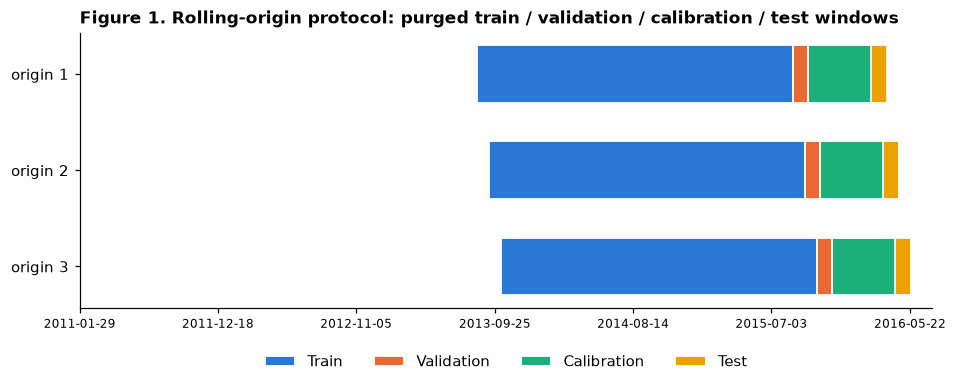

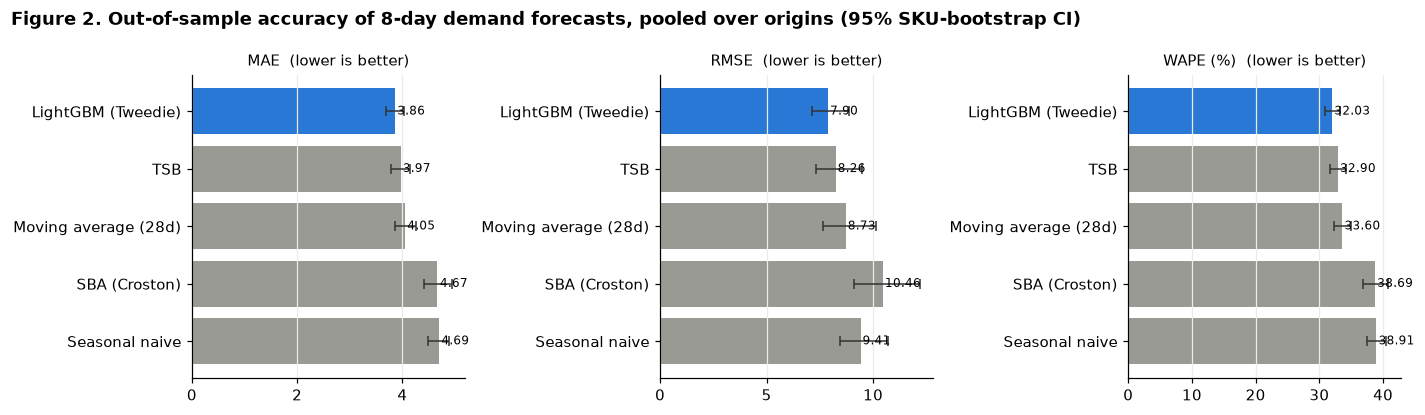

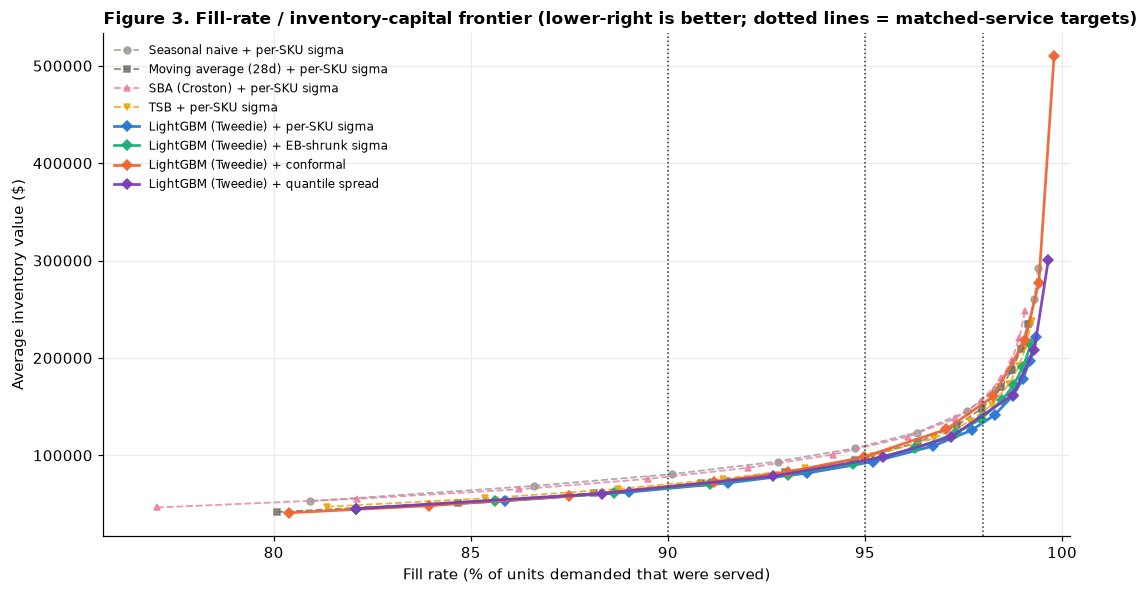

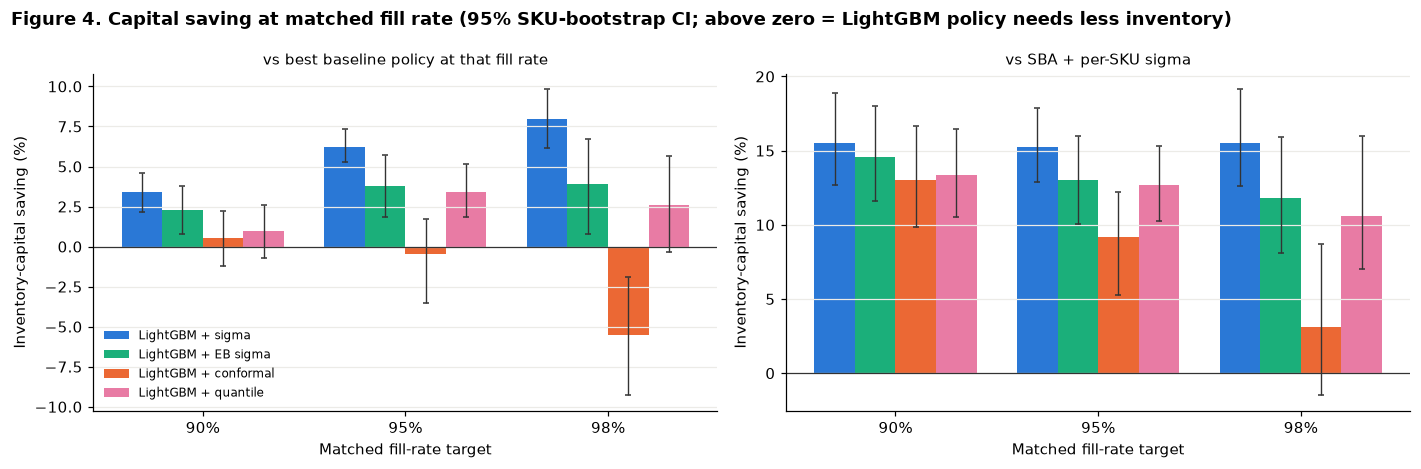

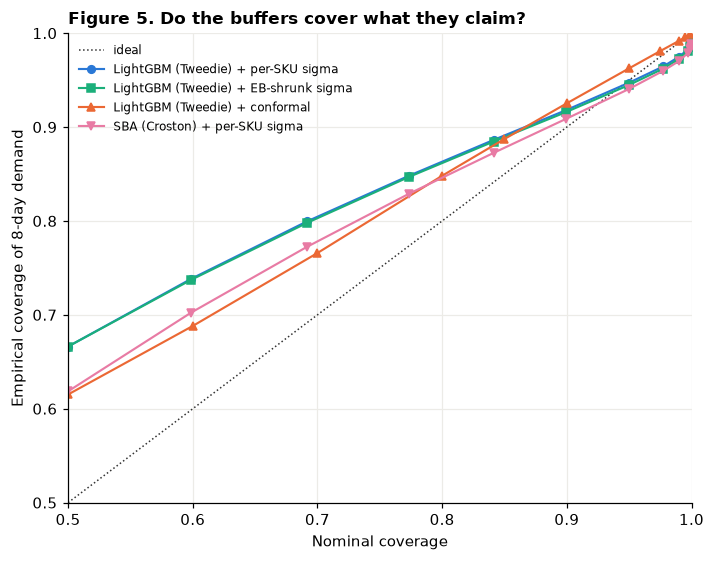

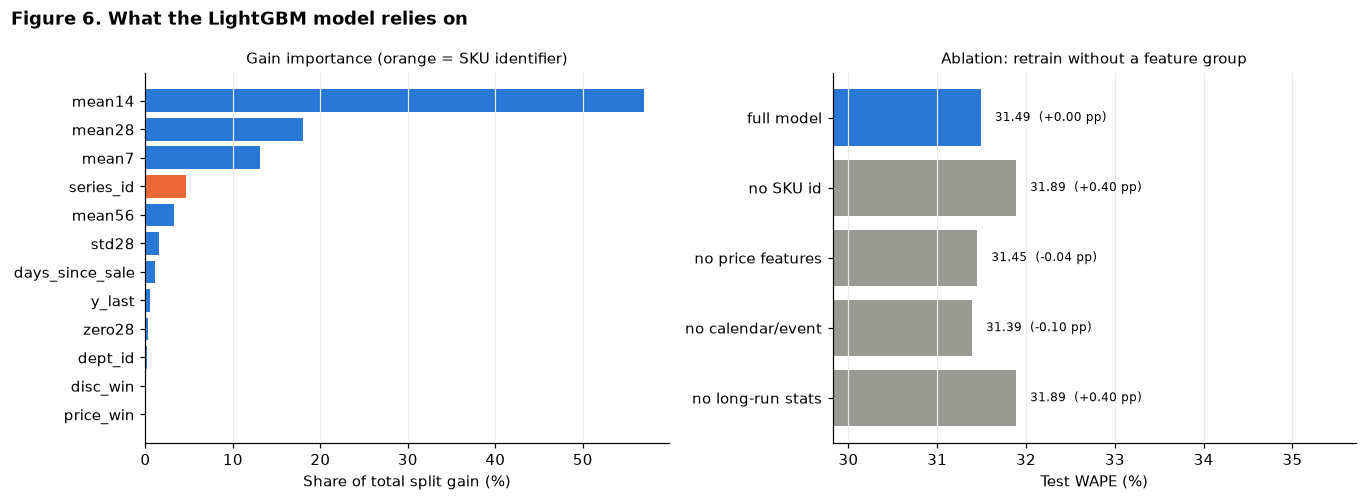

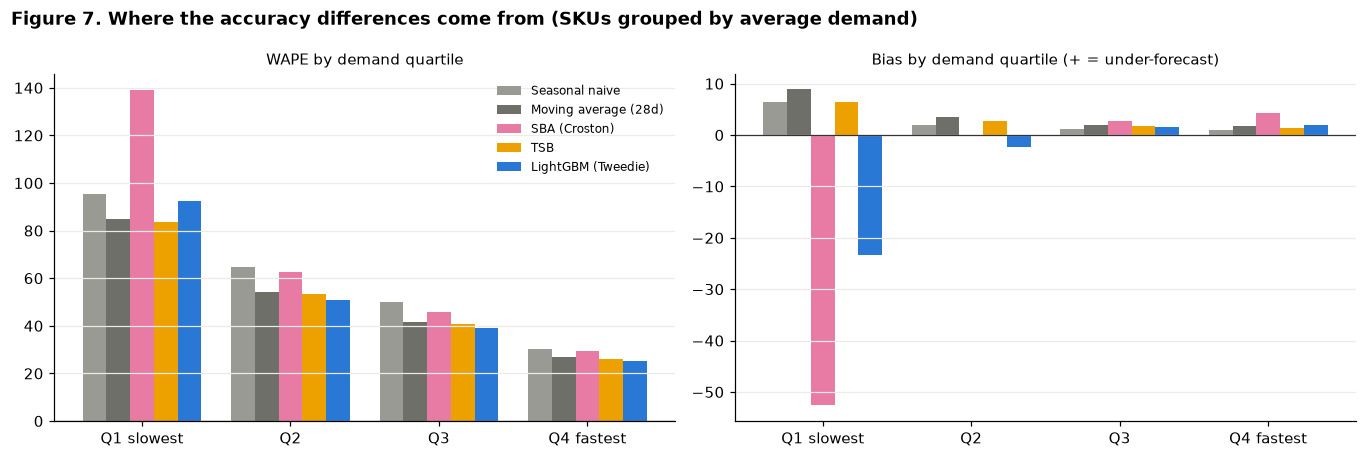

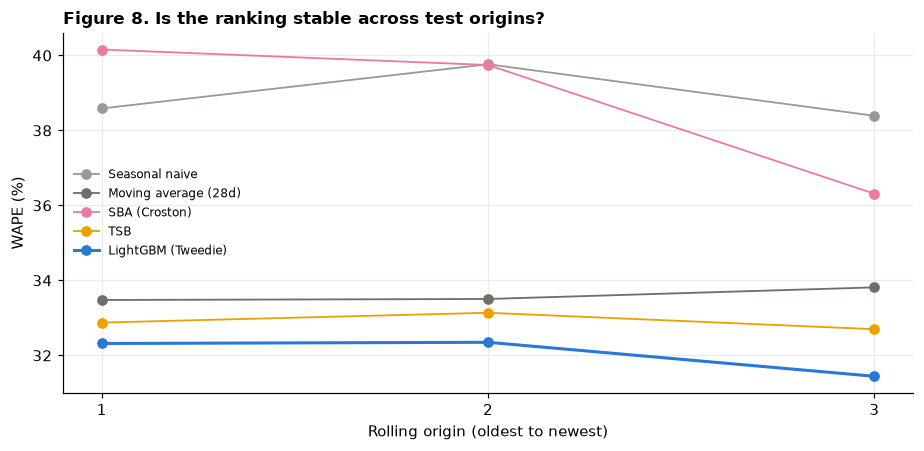


All tables and figures saved in results/


In [10]:
R, T = main()   # slow step; set CFG.n_origins = 1 for a first test